In [48]:
import sys
import os
import xarray as xr
import matplotlib.pyplot as plt
sys.path.append(os.path.join(os.environ['HOME'], 'Isca'))    # So can access functions in isca_tools which is in home/Isca directory
import isca_tools
import numpy as np
from isca_tools.utils import area_weighting
from isca_tools.plot import plot_spin_up
from isca_tools.utils.radiation import frierson_net_toa_sw_dwn
from isca_tools.utils.land import get_land_coords, get_ocean_coords

In [ ]:
# Load dataset
exp_name = os.getcwd().replace(f"{os.environ['GFDL_WORK']}jobs/", '')
ds = {'all': isca_tools.load_dataset(exp_name)[['ps', 't_surf', 'swdn_toa', 'olr']]}
namelist = isca_tools.load_namelist(exp_name)  # Need this for albedo_value
albedo = namelist['mixed_layer_nml']['albedo_value']
tau_sw = namelist['two_stream_gray_rad_nml']['atm_abs']

In [54]:
lon_surf = {'land': get_land_coords(f"{os.getcwd()}/namelist.nml", f"{os.getcwd()}/land.nc")[1], 
            'ocean': get_ocean_coords(f"{os.getcwd()}/namelist.nml", f"{os.getcwd()}/land.nc")[1]}
for key in lon_surf:
    ds[key] = ds['all'].isel(lon=np.where(np.isin(ds['all'].lon, np.unique(lon_surf[key])))[0])

In [62]:
ds['ocean'].time

<xarray.DataArray 'time' (time: 4320)> Size: 35kB
array([5.0000e-01, 1.5000e+00, 2.5000e+00, ..., 4.3175e+03, 4.3185e+03,
       4.3195e+03], shape=(4320,))
Coordinates:
  * time     (time) float64 35kB 0.5 1.5 2.5 ... 4.318e+03 4.318e+03 4.32e+03
Attributes:
    long_name:       time
    units:           days since 0001-01-01 00:00:00
    cartesian_axis:  T
    calendar_type:   360_day
    calendar:        360_day
    bounds:          time_bounds

In [63]:
n_year_days = 360
n_years = int(ds['all'].time.size / n_year_days)
ds_annual_mean = {}
for key in ds:
    ds_annual_mean[key] = xr.concat([ds[key].sel(time=slice(i*n_year_days, (i+1)*n_year_days)).mean(dim='time', keepdims=True) for i in range(n_years)], dim='time')
    ds_annual_mean[key] = ds_annual_mean[key].load()
    ds_annual_mean[key]['short_wave_net'] = frierson_net_toa_sw_dwn(ds_annual_mean[key].swdn_toa, ds_annual_mean[key].ps, albedo, tau_sw)

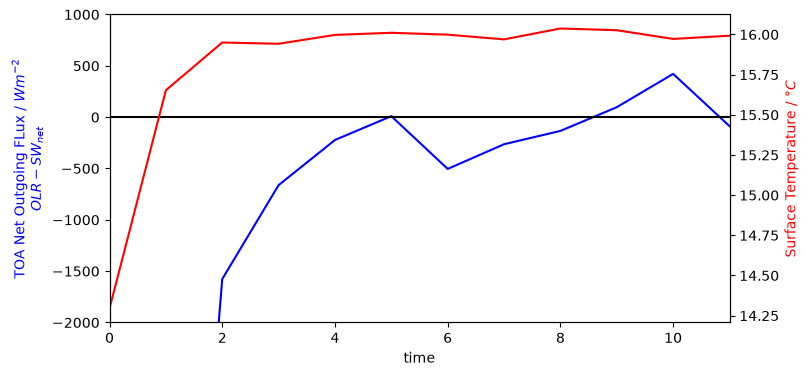

In [80]:
# Plot spinup time for each depth value
fig, ax = plt.subplots(1,1, figsize=(8, 4))
ax.set_xlabel('time [years]')
key = 'all'     # or just ocean, just land to check different heat capacities
plot_spin_up(ds_annual_mean[key].olr, ds_annual_mean[key].short_wave_net, ds_annual_mean[key].t_surf, ax)
ax.set_xlim(0, n_years-1)
ax.set_ylim(-2000, 1000)
ax.axhline(0, color='k')

(3500.0, 4200.0)

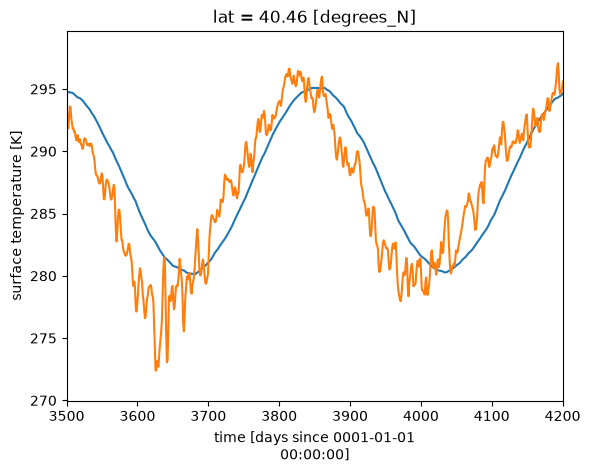

In [87]:
ds['ocean'].t_surf.mean(dim='lon').sel(lat=40, method='nearest').plot()
ds['land'].t_surf.mean(dim='lon').sel(lat=40, method='nearest').plot()
plt.gca().set_xlim(3500, 4200)